# Solving constrained mean-variance portfolios

A fully invested portfolio has expected return and variance given by:

$$
\mu_p=w^{\mathsf T}\mu,
\qquad
\sigma_p^2=w^{\mathsf T}\Sigma w,
\qquad
\mathbf 1^{\mathsf T}w=1.
$$

Here, $w$ is the vector of portfolio weights, $\mu$ is the vector of expected asset returns, $\mu_p$ is the portfolio's expected return, $\Sigma$ is the asset-return covariance matrix, $\sigma_p^2$ is portfolio variance, $\mathbf 1$ is a vector of ones, and $\mathsf T$ denotes transpose.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("23_portfolio_geometry");
using CSV, Printf
using RiskLabAI.Data: corr_to_cov,cov_to_corr,denoise_cov,denoised_corr,denoised_corr2,find_max_eval,fit_kde,score_samples,marcenko_pastur_pdf,nercome_denoised_covariance,optimal_portfolio,optimal_portfolio_denoised,pca
data_path = dataset_path("french_49_industries")
archive_hash = BookSupport.TOML.parsefile(joinpath("..","data","inputs.toml"))["datasets"]["french_49_industries"]["original_sha256"]
data_hash = uppercase(archive_hash)
@assert isfile(data_path)
@assert data_hash == "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"

function matrix_frame(matrix;metadata...)
    prefix = DataFrame([name=>fill(value,size(matrix,1)) for (name,value) in pairs(metadata)]...)
    return hcat(prefix,DataFrame(row=collect(1:size(matrix,1))),DataFrame(matrix,["x"*string(index) for index in axes(matrix,2)]))
end

function covariance_fit(covariance,q,bandwidth)
    correlation = cov_to_corr(covariance)
    values,vectors = pca(correlation)
    cutoff,variance = find_max_eval(values,q,bandwidth)
    diagnostic = RiskLabAI.Data._mp_bounded_local_min(v->RiskLabAI.Data._mp_pdf_fit_error(v,q,values,bandwidth);derivative=v->RiskLabAI.Data._mp_pdf_fit_gradient(v,q,values,bandwidth))
    @assert variance==(diagnostic.converged ? diagnostic.variance : 1.)
    factors = count(>(cutoff),values)
    return (correlation=correlation,values=values,vectors=vectors,cutoff=cutoff,variance=variance,factors=factors,converged=diagnostic.converged,latent_variance=diagnostic.variance,objective=diagnostic.objective,iterations=diagnostic.iterations)
end

function add_fliers!(figure,groups)
    for (index,values) in enumerate(groups)
        lower,upper = quantile(values,[.25,.75])
        spread = upper-lower
        outside = values[(values.<lower-1.5spread).|(values.>upper+1.5spread)]
        scatter!(figure,fill(index,length(outside)),outside;color=palette.text,markersize=3,markerstrokewidth=0,label=false)
    end
    return figure
end
function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
using SHA, TOML
using RiskLabAI.Optimization: get_optimal_portfolio_weights
using RiskLabAI.Data: form_true_matrix
include(joinpath("..","support","BookPortfolioGeometry.jl"))
using .BookPortfolioGeometry
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter20-"*replace(name,"_"=>"-"))
function portfolio_record(name,weights,expected_return,covariance)
    return (Portfolio=name,expected=dot(weights,expected_return),volatility=sqrt(dot(weights,covariance*weights)),largest=maximum(weights),smallest=minimum(weights),gross=sum(abs,weights),concentration=sum(abs2,weights),effective=1/sum(abs2,weights))
end
function portfolio_table(records)
    frame = DataFrame(records)
    rename!(frame,["Portfolio","Expected annual return","Annual volatility","Largest long weight","Smallest weight","Gross exposure","Weight concentration","Effective holdings"])
    return frame
end
function weight_frame(weights;metadata...)
    frame = DataFrame([key=>fill(value,length(weights)) for (key,value) in pairs(metadata)]...)
    return hcat(frame,DataFrame(asset=1:length(weights),weight=weights))
end
function save_noise_fit(covariance,q,name)
    fitted = covariance_fit(covariance,q,0.01)
    save_data(DataFrame(variance=[fitted.variance],cutoff=[fitted.cutoff],factors=[fitted.factors],converged=[fitted.converged],latent_variance=[fitted.latent_variance],objective=[fitted.objective],iterations=[fitted.iterations]),paths,name)
    return denoise_cov(covariance,q)
end
data_provenance = DataFrame("Field"=>["Archive","Provider","Return type","Analysis start","Analysis end","Complete dates","Industry portfolios","File checksum"],"Value"=>["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","Daily value-weighted return",string(first(industry_dates)),string(last(industry_dates)),string(size(industry_returns,1)),string(size(industry_returns,2)),data_hash])
@assert size(industry_returns)==(1760,49)
@assert first(industry_dates)==Date(2019,1,2)
@assert last(industry_dates)==Date(2025,12,31)
save_data(hcat(DataFrame(date=industry_dates),DataFrame(industry_returns,industry_names)),paths,"geometry_observations");
geometry_assets = industry_names[1:12]
geometry_sample = industry_returns[industry_dates.<=Date(2022,12,31),1:12]
geometry_mean = vec(mean(geometry_sample;dims=1)).*252
geometry_covariance = cov(geometry_sample).*252
geometry_count = length(geometry_assets)
table(data_provenance,"geometry_data_provenance","Public data used for the Chapter 20 portfolio study.")
save_data(matrix_frame(geometry_covariance),paths,"geometry_covariance")
save_data(DataFrame(asset=geometry_assets,expected_return=geometry_mean),paths,"geometry_mean");


Row,Field,Value
,String,String
1,Archive,49_Industry_Portfolios_daily_CSV.zip
2,Provider,Kenneth R. French Data Library
3,Return type,Daily value-weighted return
4,Analysis start,2019-01-02
5,Analysis end,2025-12-31
6,Complete dates,1760
7,Industry portfolios,49
8,File checksum,8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE


## The Unrestricted Frontier

The fully invested portfolio with the smallest variance and the portfolio with a chosen expected return are:

$$
w_{\mathrm{GMV}}
=\frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mathbf 1},
\qquad
w(r)
=\Sigma^{-1}C\left(C^{\mathsf T}\Sigma^{-1}C\right)^{-1}
\begin{bmatrix}1\\r\end{bmatrix},
\qquad
C=\begin{bmatrix}\mathbf 1&\mu\end{bmatrix}.
$$

Here, $w_{\mathrm{GMV}}$ is the global minimum-variance weight vector, $w(r)$ is the minimum-variance vector whose expected return is $r$, $\Sigma^{-1}$ is the inverse covariance matrix, $C$ collects the budget and return directions, and the two entries in the right-hand vector impose total weight one and expected return $r$.

Row,Check,Value
,String,Float64
1,GMV weights sum to one,1.0
2,RiskLabAI GMV agrees,2.498e-16
3,Mean-return weights sum to one,1.0
4,RiskLabAI mean-return weights agree,4.44089e-16
5,GMV first-order spread,1.38778e-17
6,Largest frontier budget error,5.55112e-16
7,Largest frontier return error,8.32667e-17


Row,Portfolio,Expected annual return,Annual volatility,Largest long weight,Smallest weight,Gross exposure,Weight concentration,Effective holdings
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Equal weight,0.132919,0.212594,0.0833333,0.0833333,1.0,0.0833333,12.0
2,Inverse variance,0.136507,0.197264,0.159722,0.0332646,1.0,0.0991565,10.0851
3,Unrestricted GMV,0.125365,0.177758,0.717866,-0.183448,1.64959,0.650151,1.5381
4,Mean-return weighted,0.231128,0.241362,0.569152,-0.219865,2.1087,0.630908,1.58502


Row,Target annual return,Achieved annual return,Annual volatility,Gross exposure
,Float64,Float64,Float64,Float64
1,0.07837,0.07837,0.191993,2.68798
2,0.0911404,0.0911404,0.185444,2.39541
3,0.103911,0.103911,0.180817,2.10283
4,0.116681,0.116681,0.178263,1.81025
5,0.129452,0.129452,0.17787,1.61545
6,0.142222,0.142222,0.179653,1.52583
7,0.154992,0.154993,0.183548,1.44007


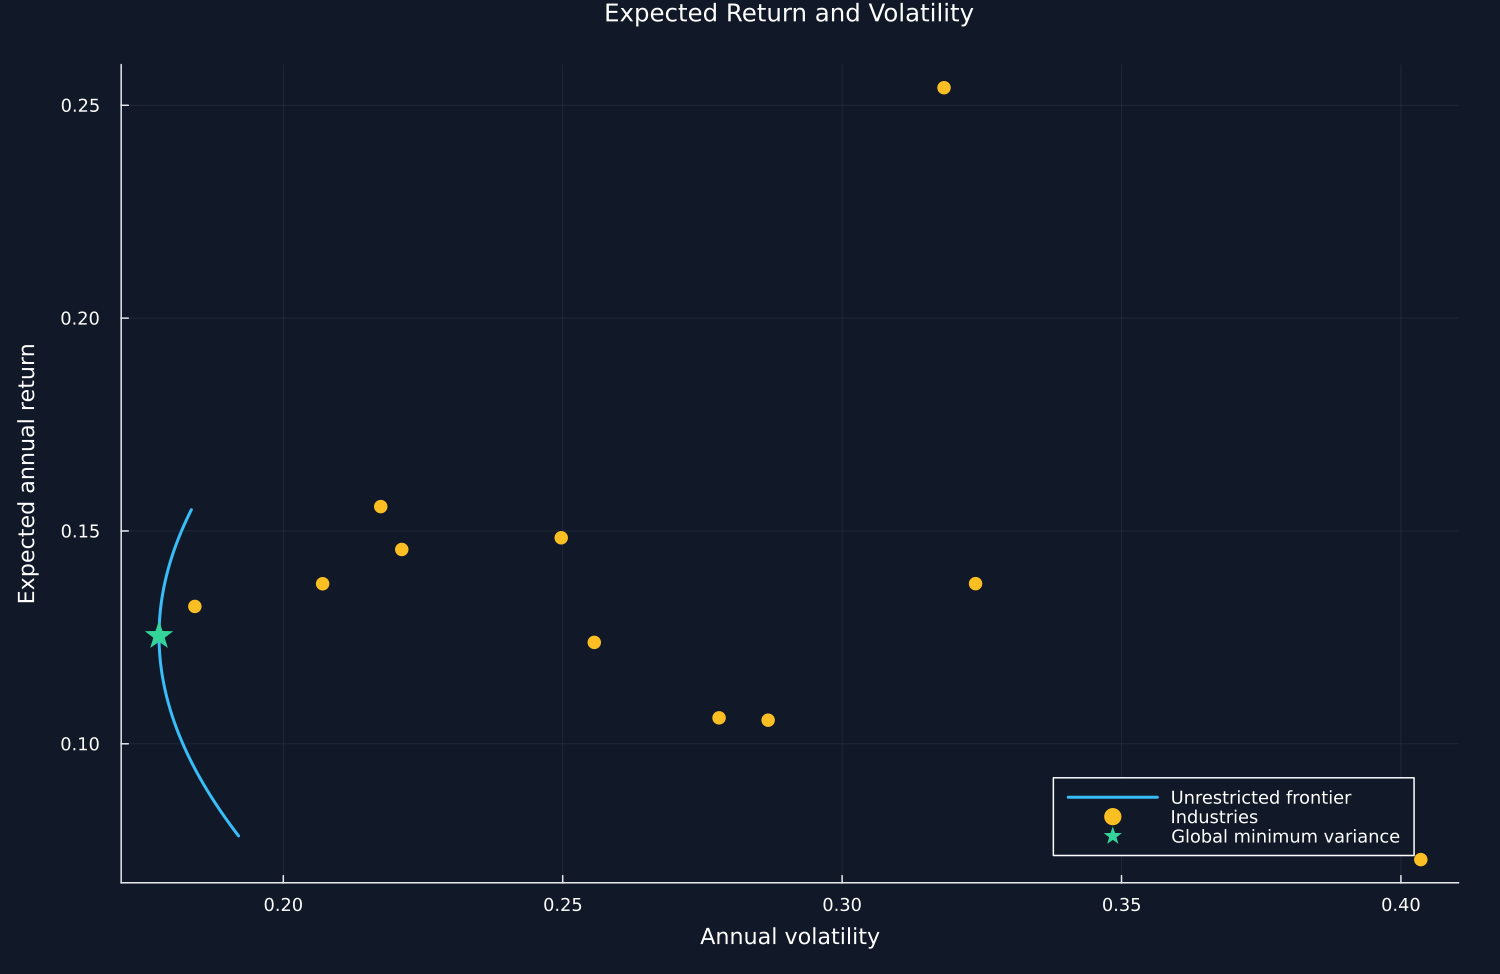

In [2]:
gmv_weights = global_minimum_variance(geometry_covariance)
library_gmv_weights = get_optimal_portfolio_weights(geometry_covariance)
mean_weights = mean_return_weighted(geometry_covariance,geometry_mean)
library_mean_weights = get_optimal_portfolio_weights(geometry_covariance;mu=geometry_mean)
target_grid = collect(range(quantile(geometry_mean,0.10),quantile(geometry_mean,0.90);length=121))
frontier_weights = reduce(vcat,[transpose(target_return_portfolio(geometry_covariance,geometry_mean,target)) for target in target_grid])
frontier_returns = frontier_weights*geometry_mean
frontier_volatility = [sqrt(dot(weights,geometry_covariance*weights)) for weights in eachrow(frontier_weights)]
asset_volatility = sqrt.(diag(geometry_covariance))
spread(values) = maximum(values)-minimum(values)
analytical_checks = DataFrame("Check"=>["GMV weights sum to one","RiskLabAI GMV agrees","Mean-return weights sum to one","RiskLabAI mean-return weights agree","GMV first-order spread","Largest frontier budget error","Largest frontier return error"],"Value"=>[sum(gmv_weights),maximum(abs,gmv_weights-library_gmv_weights),sum(mean_weights),maximum(abs,mean_weights-library_mean_weights),spread(geometry_covariance*gmv_weights),maximum(abs,vec(sum(frontier_weights;dims=2)).-1),maximum(abs,frontier_returns-target_grid)])
geometry_pairs = ["Equal weight"=>fill(1/geometry_count,geometry_count),"Inverse variance"=>inverse_variance(geometry_covariance),"Unrestricted GMV"=>gmv_weights,"Mean-return weighted"=>mean_weights]
geometry_summary = portfolio_table([portfolio_record(name,weights,geometry_mean,geometry_covariance) for (name,weights) in geometry_pairs])
frontier_audit = DataFrame("Target annual return"=>target_grid,"Achieved annual return"=>frontier_returns,"Annual volatility"=>frontier_volatility,"Gross exposure"=>vec(sum(abs,frontier_weights;dims=2)))
table(analytical_checks,"geometry_analytical_checks","Direct checks of the closed-form portfolio calculations.")
table(geometry_summary,"geometry_portfolio_summary","Public-sample portfolios before weight constraints.")
table(frontier_audit[1:20:end,:],"frontier_audit","Selected points from the unrestricted mean-variance frontier.")
save_data(reduce(vcat,[weight_frame(weights;method=name) for (name,weights) in geometry_pairs]),paths,"geometry_weights")
save_data(matrix_frame(frontier_weights),paths,"frontier_weights")
save_data(frontier_audit,paths,"frontier_audit")
figure = plot(frontier_volatility,frontier_returns;color=palette.cyan,label="Unrestricted frontier",title="Expected Return and Volatility",xlabel="Annual volatility",ylabel="Expected annual return",legend=:bottomright,size=(1000,650))
scatter!(figure,asset_volatility,geometry_mean;color=palette.amber,markersize=5,markerstrokewidth=0,label="Industries")
scatter!(figure,[sqrt(dot(gmv_weights,geometry_covariance*gmv_weights))],[dot(gmv_weights,geometry_mean)];color=palette.green,marker=:star5,markersize=10,markerstrokewidth=0,label="Global minimum variance")
save_figure(figure,paths,"mean_variance_frontier")


## Comparing two portfolio constraint sets

A long-only minimum-variance portfolio and a norm-limited portfolio solve:

$$
\min_w\;w^{\mathsf T}\Sigma w
\quad\text{subject to}\quad
\mathbf 1^{\mathsf T}w=1,
\qquad
w_i\geq0,
\qquad
\lVert w\rVert_2^2\leq c.
$$

Here, $w_i$ is the weight of asset $i$, $\lVert w\rVert_2^2=\sum_i w_i^2$ measures weight concentration, and $c$ is the largest allowed squared norm. The long-only choice uses the first two constraints, while the norm-limited choice uses the budget and norm constraints and may retain negative weights.

Row,Portfolio,Expected annual return,Annual volatility,Largest long weight,Smallest weight,Gross exposure,Weight concentration,Effective holdings
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Equal weight,0.132919,0.212594,0.0833333,0.0833333,1.0,0.0833333,12.0
2,Unrestricted GMV,0.125365,0.177758,0.717866,-0.183448,1.64959,0.650151,1.5381
3,Long-only GMV,0.13083,0.180322,0.687514,0.0,1.0,0.498101,2.00763
4,Norm-limited GMV,0.138035,0.186786,0.254732,-0.0422059,1.08441,0.15,6.66667


Row,Portfolio,Expected annual return,Annual volatility,Largest long weight,Smallest weight,Gross exposure,Weight concentration,Effective holdings,Squared norm limit,Constraint gap
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Norm limit 0.083,0.132919,0.212594,0.0833333,0.0833333,1.0,0.0833333,12.0,0.0833333,-2.77556e-17
2,Norm limit 0.100,0.138333,0.196053,0.151832,0.0261457,1.0,0.1,10.0,0.1,1.38778e-17
3,Norm limit 0.150,0.138035,0.186786,0.254732,-0.0422059,1.08441,0.15,6.66667,0.15,0.0
4,Norm limit 0.250,0.134057,0.181425,0.403151,-0.0951162,1.19023,0.25,4.0,0.25,5.55112e-17
5,Norm limit 0.500,0.127867,0.178067,0.626247,-0.123346,1.48314,0.5,2.0,0.5,1.66533e-16
6,Norm limit 1.000,0.125365,0.177758,0.717866,-0.183448,1.64959,0.650151,1.5381,1.0,0.349849


Row,Check,Value
,String,Float64
1,Long-only budget error,1.11022e-16
2,Smallest long-only weight,0.0
3,Long-only objective improvement over equal weight,0.0126802
4,Norm-limited budget error,2.22045e-16
5,Chosen squared norm,0.15
6,Chosen norm limit,0.15
7,Norm constraint gap,0.0


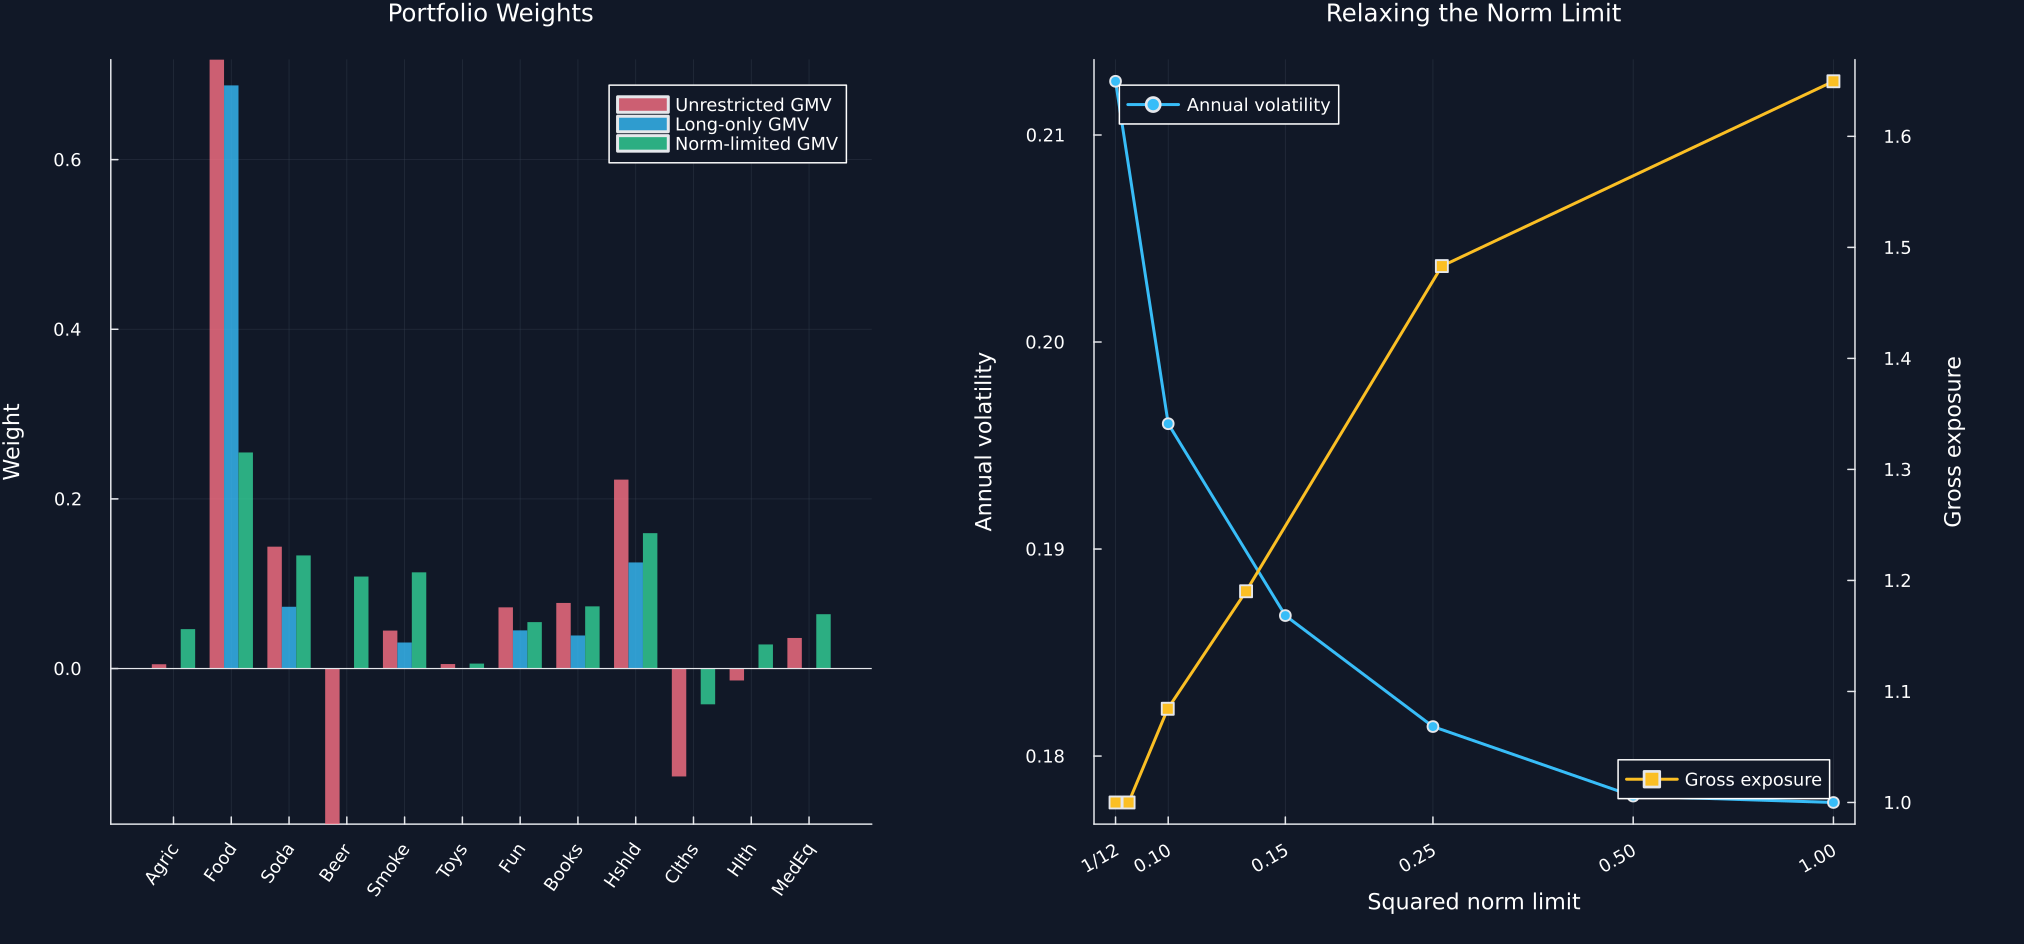

In [3]:
long_only_weights = long_only_minimum_variance(geometry_covariance)
norm_limits = [1/geometry_count,0.10,0.15,0.25,0.50,1.00]
norm_weight_map = Dict(limit=>norm_limited_minimum_variance(geometry_covariance,limit) for limit in norm_limits)
norm_path = portfolio_table([portfolio_record(@sprintf("Norm limit %.3f",limit),norm_weight_map[limit],geometry_mean,geometry_covariance) for limit in norm_limits])
norm_path[!,"Squared norm limit"] = norm_limits
norm_path[!,"Constraint gap"] = [limit-sum(abs2,norm_weight_map[limit]) for limit in norm_limits]
chosen_norm_limit = 0.15
chosen_norm_weights = norm_weight_map[chosen_norm_limit]
constrained_pairs = ["Equal weight"=>fill(1/geometry_count,geometry_count),"Unrestricted GMV"=>gmv_weights,"Long-only GMV"=>long_only_weights,"Norm-limited GMV"=>chosen_norm_weights]
constrained_summary = portfolio_table([portfolio_record(name,weights,geometry_mean,geometry_covariance) for (name,weights) in constrained_pairs])
equal_weights = fill(1/geometry_count,geometry_count)
constrained_checks = DataFrame("Check"=>["Long-only budget error","Smallest long-only weight","Long-only objective improvement over equal weight","Norm-limited budget error","Chosen squared norm","Chosen norm limit","Norm constraint gap"],"Value"=>[abs(sum(long_only_weights)-1),minimum(long_only_weights),dot(equal_weights,geometry_covariance*equal_weights)-dot(long_only_weights,geometry_covariance*long_only_weights),abs(sum(chosen_norm_weights)-1),sum(abs2,chosen_norm_weights),chosen_norm_limit,chosen_norm_limit-sum(abs2,chosen_norm_weights)])
table(constrained_summary,"constrained_portfolio_summary","Public-sample portfolios with long-only and norm constraints.")
table(norm_path,"norm_limit_path","Portfolio changes as the squared weight-norm limit is relaxed.")
table(constrained_checks,"constrained_checks","Constraint and objective checks for the public quadratic programs.")
save_data(reduce(vcat,[weight_frame(weights;method=name) for (name,weights) in constrained_pairs]),paths,"constrained_weights")
save_data(reduce(vcat,[weight_frame(norm_weight_map[limit];limit) for limit in norm_limits]),paths,"norm_path_weights")
p1 = plot(;title="Portfolio Weights",ylabel="Weight",xticks=(1:geometry_count,geometry_assets),xrotation=55,legend=:topright)
for (offset,name,weights,color) in [(-1,"Unrestricted GMV",gmv_weights,palette.rose),(0,"Long-only GMV",long_only_weights,palette.cyan),(1,"Norm-limited GMV",chosen_norm_weights,palette.green)]
    bar!(p1,collect(1:geometry_count).+0.25offset,weights;bar_width=0.25,color,alpha=0.8,linealpha=0,label=name)
end
hline!(p1,[0.0];color=palette.text,linewidth=0.8,label=false)
p2 = plot(norm_limits,norm_path[!,"Annual volatility"];color=palette.cyan,marker=:circle,markersize=4,label="Annual volatility",legend=:topleft,xscale=:log10,title="Relaxing the Norm Limit",xlabel="Squared norm limit",ylabel="Annual volatility",xticks=(norm_limits,["1/12","0.10","0.15","0.25","0.50","1.00"]),xrotation=30)
plot!(twinx(p2),norm_limits,norm_path[!,"Gross exposure"];color=palette.amber,marker=:square,markersize=4,label="Gross exposure",legend=:bottomright,ylabel="Gross exposure",grid=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1350,630),bottom_margin=10Plots.mm,right_margin=15Plots.mm),paths,"constrained_weights_norm_path")


## Checking active constraints from first-order conditions

At an unrestricted minimum, marginal variance is equal across assets, while constrained solutions add terms for active limits:

$$
2\Sigma w-\lambda\mathbf 1-\nu+2\eta w=0,
\qquad
\nu_iw_i=0,
\qquad
\eta\left(c-w^{\mathsf T}w\right)=0.
$$

Here, $\lambda$ is the multiplier for the budget constraint, $\nu_i\geq0$ is the multiplier for the nonnegative weight of asset $i$, and $\eta\geq0$ is the multiplier for the norm limit. The last two equalities say that a multiplier can be positive only when its constraint is active.

In [4]:
marginal_variance = 2 .*geometry_covariance*gmv_weights
active_long_only = count(<(1e-8),long_only_weights)
section_01_summary = DataFrame("Quantity"=>["Public observations","Industries in geometry study","Covariance condition number","Unrestricted GMV volatility","Long-only GMV volatility","Norm-limited GMV volatility","Long-only zero weights","GMV marginal-variance spread"],"Value"=>[size(geometry_sample,1),geometry_count,cond(geometry_covariance),sqrt(dot(gmv_weights,geometry_covariance*gmv_weights)),sqrt(dot(long_only_weights,geometry_covariance*long_only_weights)),sqrt(dot(chosen_norm_weights,geometry_covariance*chosen_norm_weights)),active_long_only,spread(marginal_variance)])
table(section_01_summary,"section_01_summary","Main numerical results for the public portfolio-geometry study.")


Row,Quantity,Value
,String,Float64
1,Public observations,1008.0
2,Industries in geometry study,12.0
3,Covariance condition number,95.6346
4,Unrestricted GMV volatility,0.177758
5,Long-only GMV volatility,0.180322
6,Norm-limited GMV volatility,0.186786
7,Long-only zero weights,6.0
8,GMV marginal-variance spread,2.77556e-17


## Tests

In [5]:
@assert data_hash=="8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
@assert size(industry_returns)==(1760,49)
@assert size(geometry_sample,2)==12
@assert eigmin(Symmetric(geometry_covariance))>0
@assert sum(gmv_weights)≈1
@assert maximum(abs,gmv_weights-library_gmv_weights)<1e-10
@assert sum(mean_weights)≈1
@assert maximum(abs,mean_weights-library_mean_weights)<1e-10
@assert spread(geometry_covariance*gmv_weights)<1e-10
@assert maximum(abs,vec(sum(frontier_weights;dims=2)).-1)<1e-10
@assert maximum(abs,frontier_returns-target_grid)<1e-10
@assert sum(long_only_weights)≈1
@assert minimum(long_only_weights)>=-1e-9
@assert sum(chosen_norm_weights)≈1
@assert sum(abs2,chosen_norm_weights)<=chosen_norm_limit+1e-8
@assert all(norm_path[!,"Constraint gap"].>=-1e-8)
@assert active_long_only>=1
@assert nrow(frontier_audit)==121
@assert nrow(norm_path)==6
@assert isfile(joinpath(paths.figures,"mean_variance_frontier.pdf"))
@assert isfile(joinpath(paths.figures,"constrained_weights_norm_path.pdf"))
@assert isfile(joinpath(paths.tables,"geometry_portfolio_summary.tex"))
@assert isfile(joinpath(paths.tables,"constrained_portfolio_summary.tex"))
